# 机器学习课堂笔记：KNN 完整流程

本 Notebook 按《机器学习课堂笔记(3)》整理，主线是：

**数据 → 距离 → k 个近邻 → 投票/加权 → 评估 → 标准化 → Pipeline 防泄露 → 网格搜索**

前置知识：Python、NumPy、Pandas（DataFrame / Series）、Matplotlib。

依赖安装：

```bash
pip install numpy pandas scikit-learn matplotlib
```

> 说明：为了让 Notebook 可以直接运行，课程中的核心实现（距离函数、手写 KNN）也放在本文件里，不依赖外部模块。

In [1]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.datasets import load_iris
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.base import BaseEstimator, ClassifierMixin

# 让 matplotlib 正常显示中文和负号
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
np.set_printoptions(precision=3, suppress=True)

## 1. 机器学习概述

### 写规则 vs 从数据中学

识别诈骗短信时，如果靠程序员写 `if-else`，骗子只要改写法（“中奖” → “中 奖” → “zhong 奖”），规则就会越堆越多、互相冲突。

机器学习换了一个思路：收集大量已标注的短信，让算法自己总结哪些词语和组合与诈骗有关。骗子换说法，就补充新数据重新训练。

> **机器学习 = 从数据中自动总结规律（训练），再用规律对新数据做判断（预测）。**

### 经典定义：T、P、E

如果一个程序在任务 **T** 上以 **P** 衡量的性能，随着经验 **E** 的增加而提高，我们就说它从经验 E 中学习。

做项目之前先把 T、P、E 写清楚：

- **T（任务）**：要做什么，例如“判断短信是否为诈骗”。
- **P（性能指标）**：怎么衡量做得好，例如“诈骗短信被找出来的比例”。指标要能算出来。
- **E（经验）**：从哪里学，例如“一批已标注的短信”。

### 模型是什么

模型就是一个带参数的函数：

$$y = f(x;\theta)$$

- $x$：输入特征，一行数据；
- $\theta$：模型从数据里学到的参数；
- $y$：输出，类别或数值。

训练是在已有数据上寻找一组参数 $\theta$，让预测尽可能接近真实答案；预测是把新数据的 $x$ 代进去算出 $y$。

一个机器学习系统可以拆成五个零件，循环运转：

| 序号 | 名称 | 记号 | 说明 |
|---|---|---|---|
| 1 | 数据集 | $D$ | 大量“输入 → 标准答案”样本 |
| 2 | 模型 | $f(x;\theta)$ | 带可调参数 $\theta$ 的函数 |
| 3 | 预测值 | $\hat{y}$ | 模型当前给出的答案 |
| 4 | 损失函数 | $L(\hat{y}, y)$ | 量化“猜得有多离谱” |
| 5 | 优化器 | SGD / Adam | 沿梯度反方向微调 $\theta$ |

> KNN 是惰性学习：`fit` 只保存训练数据，真正的距离计算和投票发生在 `predict`，所以它没有显式的梯度优化过程。

### 术语与 DataFrame 的对应

| 术语 | 在 DataFrame 里 | 二手房估价例子 |
|---|---|---|
| 样本（sample） | 一行 | 一套房子 |
| 特征（feature, X） | 作为输入的那些列 | 面积、楼层、房龄 |
| 标签（label, y） | 要预测的那一列 | 成交价格 |
| 训练（fit） | 用已知标签的行学习 | 用过去成交记录训练 |
| 预测（predict） | 对新行给出 $\hat{y}$ | 给刚挂牌的房子估价 |

### 三种学习方式

1. **监督学习**：有答案的练习题。题目（特征）+ 参考答案（标签）。
2. **无监督学习**：没有答案，自己归纳分类、找规律。
3. **强化学习**：在环境中反复试错，根据奖励/惩罚调整策略。

In [2]:
# 用 Pandas 查看鸢尾花数据集：150 个样本、4 个特征、1 个三分类标签
iris = load_iris(as_frame=True)
df = iris.frame

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [3]:
print("数据形状:", df.shape)
print("特征名:", list(iris.feature_names))
print("类别名:", list(iris.target_names))
print("类别分布:")
print(df["target"].value_counts().sort_index())

数据形状: (150, 5)
特征名: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
类别名: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
类别分布:
target
0    50
1    50
2    50
Name: count, dtype: int64


## 2. KNN 的核心思想与距离度量

K 近邻（K-Nearest Neighbors，KNN）是一种**基于实例的监督学习算法**，既可以分类，也可以回归。

核心思想：**相似的数据点在特征空间中距离相近**，所以可以用邻近样本的标签来预测新样本。

> “近朱者赤，近墨者黑”的数学版：看一个新样本周围都是谁，就判断它大概率也是那样。

KNN 做一次预测分四步：

1. 计算待测样本到每个训练样本的距离；
2. 选出距离最小的 $k$ 个样本；
3. 分类任务：让这 $k$ 个邻居投票（可以加权）；
4. 票数最多的类别就是预测结果。

### 距离怎么量

**欧氏距离**（$p=2$）：直线距离，勾股定理的推广。

$$d(q,x)=\sqrt{\sum_{j=1}^{D}(x_j-q_j)^2}$$

**曼哈顿距离**（$p=1$）：横平竖直走，像出租车沿街道行驶。

$$d(q,x)=\sum_{j=1}^{D}|x_j-q_j|$$

**切比雪夫距离**（$p=\infty$）：只看差距最大的那一维，像国际象棋的国王。

$$d(q,x)=\max_j |x_j-q_j|$$

三者可以统一成**闵氏距离**：

$$d(q,x)=\left(\sum_{j=1}^{D}|x_j-q_j|^p\right)^{1/p}$$

在 sklearn 里，这就是 KNN 的参数 `p`：

- `p=1`：曼哈顿距离；
- `p=2`：欧氏距离（默认）；
- `metric="chebyshev"`：切比雪夫距离。

In [4]:
def minkowski_distance(X, q, p=2):
    """X: (n_samples, n_features)，q: (n_features,)；返回每个样本到 q 的距离。"""
    X = np.atleast_2d(np.asarray(X, dtype=float))
    q = np.asarray(q, dtype=float).reshape(1, -1)
    diff = np.abs(X - q)
    if np.isinf(p):
        return diff.max(axis=1)
    return (diff ** p).sum(axis=1) ** (1.0 / p)


def euclidean_distance(X, q):
    return minkowski_distance(X, q, p=2)


def manhattan_distance(X, q):
    return minkowski_distance(X, q, p=1)


def chebyshev_distance(X, q):
    return minkowski_distance(X, q, p=np.inf)

In [5]:
# 3-4-5 直角三角形：验证三把尺子
X_demo = np.array([[0.0, 0.0], [3.0, 4.0]])
q_demo = np.array([0.0, 0.0])

print("欧氏距离:   ", euclidean_distance(X_demo, q_demo))
print("曼哈顿距离: ", manhattan_distance(X_demo, q_demo))
print("切比雪夫距离:", chebyshev_distance(X_demo, q_demo))

欧氏距离:    [0. 5.]
曼哈顿距离:  [0. 7.]
切比雪夫距离: [0. 4.]


In [6]:
# 4 维鸢尾花：用 NumPy 广播一次算完 150 个距离
X, y = load_iris(return_X_y=True)

new_flower = np.array([6.0, 3.3, 4.5, 1.5])
distances = np.sqrt(((X - new_flower) ** 2).sum(axis=1))
nearest = np.argsort(distances, kind="stable")[:5]

print("最近 5 朵花的索引:", nearest)
print("最近 5 朵花的标签:", y[nearest])
print("对应距离:", distances[nearest])

最近 5 朵花的索引: [85 91 56 78 51]
最近 5 朵花的标签: [1 1 1 1 1]
对应距离: [0.141 0.346 0.374 0.4   0.412]


In [7]:
# 换几把尺子做 10 折交叉验证：鸢尾花特征同量纲，差距通常不大
cv = StratifiedKFold(10, shuffle=True, random_state=0)
metrics = {
    "曼哈顿 p=1": {"p": 1},
    "欧氏 p=2": {"p": 2},
    "切比雪夫": {"metric": "chebyshev"},
    "余弦": {"metric": "cosine"},
}

for name, params in metrics.items():
    acc = cross_val_score(
        KNeighborsClassifier(n_neighbors=5, **params), X, y, cv=cv
    ).mean()
    print(f"{name:<10} 准确率={acc:.3f}")

曼哈顿 p=1    准确率=0.953
欧氏 p=2     准确率=0.953
切比雪夫       准确率=0.960
余弦         准确率=0.960


### 三把尺子的适用场景

| 距离 | 关注点 | 适用场景 | 注意 |
|---|---|---|---|
| 欧氏距离 `p=2` | 空间直线远近 | 特征连续、单位相同（鸢尾花） | 异常值会被平方放大 |
| 曼哈顿距离 `p=1` | 各维差值之和 | 多维度评分、城市街区路程 | 对异常值更稳健 |
| 切比雪夫距离 | 差距最大的那一维 | 零件质检、超限告警（木桶效应） | 只看最差项 |

**距离的选择本身也是超参数。** 尺子不同，“谁更近”可能不同，预测结果也可能不同。

## 3. 1-NN、平票与加权投票

### 只听最近的一个：1-近邻

最省事的规则：离谁最近，就跟谁一类，叫 **1-NN**。

把平面上每个位置都这样问一遍，再按答案涂色，平面会被分成一块块“地盘”。每个训练样本管着离它最近的那块多边形，叫**泰森多边形**。两块地盘的分界线由一段段中垂线拼成。

1-NN 的致命弱点：**怕噪声**。一个被标错的点就能挖走一整块地盘。于是多问几个邻居，少数服从多数——这个“几个”就是 KNN 里的 $k$。

### 平票怎么办

二分类时取奇数 $k$ 可以避免平票；三分类时奇数也不保险（例如 $k=3$ 且三个邻居各属一类）。

sklearn 遇到平票时，会选择**编号更小的类别**。编号来自 `classes_`：sklearn 会把所有标签排序后编号，所以用汉字当标签时，排序依据是字符编码，结果可能出乎意料。

### 加权 KNN：越近的邻居说话越算数

普通 KNN：一人一票。加权 KNN（`weights="distance"`）：距离越近，权重越大，常用权重

$$w = \frac{1}{d}$$

其中 $d$ 是邻居到待测点的距离。

例如 $k=3$：朱（$d=1$）、墨（$d=2$）、墨（$d=2.828$）。

- 一人一票：墨 2 票，朱 1 票 → 判墨；
- 加权：朱 $1/1=1.0$，墨 $1/2+1/2.828\approx0.854$ → 判朱。

In [8]:
# 朱 / 墨 玩具数据：k=4 时 2 票对 2 票
X_toy = np.array(
    [[3, 4], [7, 4], [3, 7], [8, 3], [4, 2], [6, 2], [4, 8], [8, 1]],
    dtype=float,
)
y_toy = np.array(["朱"] * 4 + ["墨"] * 4)
q_toy = np.array([[4.0, 4.0]])

for weights in ["uniform", "distance"]:
    clf = KNeighborsClassifier(n_neighbors=4, weights=weights).fit(X_toy, y_toy)
    print(
        f"weights={weights:<9} 预测={clf.predict(q_toy)[0]}  "
        f"classes_={clf.classes_}"
    )

weights=uniform   预测=墨  classes_=['墨' '朱']
weights=distance  预测=朱  classes_=['墨' '朱']


In [9]:
# 讲义中的加权手算例子
votes = {"朱": 1 / 1.0, "墨": 1 / 2.0 + 1 / 2.828}
print("加权票数:", votes)
print("预测:", max(votes, key=votes.get))

加权票数: {'朱': 1.0, '墨': 0.8536067892503536}
预测: 朱


## 4. 手写一个 KNN 分类器

下面把 KNN 的核心逻辑完整写一遍，并与 sklearn 的结果对照。支持：

- `metric`：`euclidean` / `manhattan` / `chebyshev`；
- `weights`：`uniform`（一人一票）/ `distance`（按 $1/d$ 加权）；
- 平票时取编号更小的类别，与 sklearn 一致。

In [10]:
_METRIC_P = {"euclidean": 2.0, "manhattan": 1.0, "chebyshev": np.inf}


class KNNClassifier(ClassifierMixin, BaseEstimator):
    """手写 K 近邻分类器，接口与 sklearn 的 KNeighborsClassifier 对齐。"""

    def __init__(self, n_neighbors=5, metric="euclidean", weights="uniform"):
        self.n_neighbors = n_neighbors
        self.metric = metric
        self.weights = weights

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)

        if X.ndim != 2 or y.ndim != 1:
            raise ValueError("X 应为二维数组，y 应为一维数组")
        if len(X) != len(y):
            raise ValueError("X 与 y 的样本数不一致")
        if not 1 <= self.n_neighbors <= len(X):
            raise ValueError("n_neighbors 必须在 1 到训练样本数之间")
        if self.metric not in _METRIC_P:
            raise ValueError(f"不支持的 metric: {self.metric}")
        if self.weights not in ("uniform", "distance"):
            raise ValueError(f"不支持的 weights: {self.weights}")

        # np.unique 会排序，classes_ 的顺序与 sklearn 一致
        self.classes_, self._encoded_y = np.unique(y, return_inverse=True)
        self._X = X
        return self

    def _distances(self, X):
        p = _METRIC_P[self.metric]
        diff = np.abs(X[:, None, :] - self._X[None, :, :])
        if np.isinf(p):
            return diff.max(axis=2)
        return (diff ** p).sum(axis=2) ** (1.0 / p)

    def _vote(self, distances):
        order = np.argsort(distances, kind="stable")[: self.n_neighbors]
        labels = self._encoded_y[order]
        d = distances[order]

        if self.weights == "distance":
            exact = d == 0
            if exact.any():
                # 有完全重合的训练样本时只由它们投票
                labels = labels[exact]
                w = None
            else:
                w = 1.0 / d
        else:
            w = None

        counts = np.bincount(labels, weights=w, minlength=len(self.classes_))
        # 平票时 argmax 返回编号更小的类别
        return self.classes_[int(np.argmax(counts))]

    def predict(self, X):
        X = np.atleast_2d(np.asarray(X, dtype=float))
        return np.array([self._vote(d) for d in self._distances(X)])

    def score(self, X, y):
        return float(np.mean(self.predict(X) == np.asarray(y)))

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=0
)

ours = KNNClassifier(5).fit(X_train, y_train).predict(X_test)
ref = KNeighborsClassifier(5).fit(X_train, y_train).predict(X_test)

print("手写 KNN 与 sklearn 的预测完全一致:", np.array_equal(ours, ref))
print("测试集准确率:", accuracy_score(y_test, ours))

手写 KNN 与 sklearn 的预测完全一致: True
测试集准确率: 1.0


## 5. 完整案例：学生能否通过期末考核

- 特征：$X_1$ 平时分，$X_2$ 作业完成率；
- 标签：0 = 挂科，1 = 通过；
- 用 KNN 对新学生 $(70, 75)$ 做预测。

当 $k=8$ 时恰好 4 个通过、4 个挂科，平票按编号更小的 0（挂科）处理；改成加权投票后，距离更近的通过样本权重更大，结果变成通过。

In [12]:
X_student = np.array(
    [
        [90, 95], [85, 88], [78, 90], [82, 76],
        [40, 30], [50, 45], [35, 60], [55, 35],
    ],
    dtype=float,
)
y_student = np.array([1, 1, 1, 1, 0, 0, 0, 0])
student = np.array([[70.0, 75.0]])
result_map = ["挂科", "通过"]

for k in range(1, 9):
    pred = KNNClassifier(k).fit(X_student, y_student).predict(student)[0]
    print(f"k={k}: {result_map[pred]}")

k=1: 通过
k=2: 通过
k=3: 通过
k=4: 通过
k=5: 通过
k=6: 通过
k=7: 通过
k=8: 挂科


In [13]:
for weights in ["uniform", "distance"]:
    clf = KNeighborsClassifier(n_neighbors=8, weights=weights).fit(
        X_student, y_student
    )
    print(f"sklearn k=8, weights={weights:<9} 预测={result_map[clf.predict(student)[0]]}")

sklearn k=8, weights=uniform   预测=挂科
sklearn k=8, weights=distance  预测=通过


## 6. $k$ 的选择与模型评估

### $k$ 太小和太大，各有各的问题

- **k 太小**：决策边界弯弯曲曲，围着每个样本拐弯，把噪声当成规律 → **过拟合**。
- **k 太大**：边界越来越平滑，忽略局部特征，极端情况下所有样本都投给全局最多的类 → **欠拟合**。

### 能不能用训练集选 k

不能。用训练集评估是“自己考自己”：

- k=1 时每个训练样本的最近邻就是自己，训练集准确率必然接近 1.0；
- k 很大时训练集准确率也会下降，但这并不说明模型对新数据好。

正确做法是留出测试集，或用交叉验证。测试集只能用于最终评估，不能参与选参。

> 注意：讲义 p14 把 0.920 / 0.820 等数字标为“训练集准确率”，但从数值看更像是测试集/留出集准确率。k=1 在训练集上自评必然接近 1.0，本 Notebook 会分别计算训练集和交叉验证准确率，便于对照。

### 交叉验证

把训练数据平均切成 $K$ 份，轮流拿其中 1 份当“模拟考”，其余 $K-1$ 份当邻居，得到 $K$ 个分数再取平均。这就是 $K$ 折交叉验证。分层抽样（`StratifiedKFold`）保证每份里各类别比例一致。

In [14]:
cv = StratifiedKFold(10, shuffle=True, random_state=0)
ks = [1, 3, 5, 7, 9, 11, 15, 21, 31, 51, 75, 101]

train_scores = []
cv_scores = []
for k in ks:
    # 自己考自己：训练集准确率
    train_scores.append(KNNClassifier(k).fit(X, y).score(X, y))
    # 10 折交叉验证：更接近泛化能力
    cv_scores.append(
        cross_val_score(KNNClassifier(k), X, y, cv=cv).mean()
    )

best_k = ks[int(np.argmax(cv_scores))]
print(f"最佳 k={best_k}，交叉验证准确率={max(cv_scores):.3f}\n")
for k, tr, cv_score in zip(ks, train_scores, cv_scores):
    print(f"k={k:>3}  训练集={tr:.3f}  交叉验证={cv_score:.3f}")

最佳 k=15，交叉验证准确率=0.967

k=  1  训练集=1.000  交叉验证=0.960
k=  3  训练集=0.960  交叉验证=0.960
k=  5  训练集=0.967  交叉验证=0.953
k=  7  训练集=0.973  交叉验证=0.960
k=  9  训练集=0.980  交叉验证=0.953
k= 11  训练集=0.973  交叉验证=0.960
k= 15  训练集=0.987  交叉验证=0.967
k= 21  训练集=0.980  交叉验证=0.967
k= 31  训练集=0.960  交叉验证=0.933
k= 51  训练集=0.953  交叉验证=0.933
k= 75  训练集=0.907  交叉验证=0.900
k=101  训练集=0.660  交叉验证=0.660


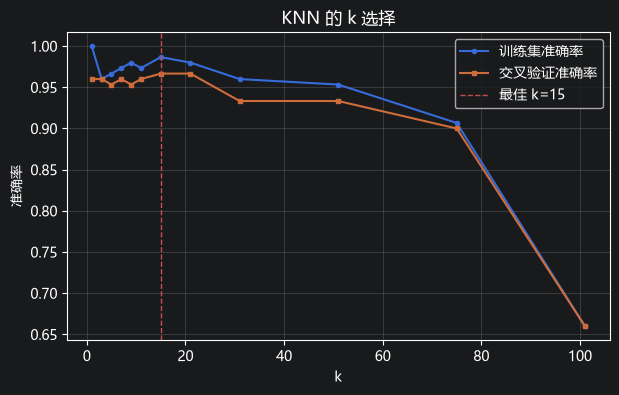

In [15]:
plt.figure(figsize=(7, 4))
plt.plot(ks, train_scores, marker="o", markersize=3, label="训练集准确率")
plt.plot(ks, cv_scores, marker="s", markersize=3, label="交叉验证准确率")
plt.axvline(best_k, color="#C44E52", linestyle="--", linewidth=1, label=f"最佳 k={best_k}")
plt.xlabel("k")
plt.ylabel("准确率")
plt.title("KNN 的 k 选择")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [16]:
# 留出法：训练集 / 测试集，并查看混淆矩阵
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

clf = KNNClassifier(7).fit(X_train, y_train)
y_pred = clf.predict(X_test)

print("测试集准确率:", accuracy_score(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
pd.DataFrame(
    cm,
    index=[f"真实: {name}" for name in iris.target_names],
    columns=[f"预测: {name}" for name in iris.target_names],
)

测试集准确率: 0.9666666666666667


,预测: setosa,预测: versicolor,预测: virginica
真实: setosa,10,0,0
真实: versicolor,0,10,0
真实: virginica,0,1,9


In [17]:
# 训练集与测试集对照：k=1 过拟合，k=101 欠拟合
for k in [1, 7, 101]:
    model = KNNClassifier(k).fit(X_train, y_train)
    print(
        f"k={k:>3}  训练集={model.score(X_train, y_train):.3f}  "
        f"测试集={model.score(X_test, y_test):.3f}"
    )

k=  1  训练集=1.000  测试集=0.967
k=  7  训练集=0.975  测试集=0.967
k=101  训练集=0.658  测试集=0.600


### 混淆矩阵

混淆矩阵是一张“对错统计表”：

- **行 = 真实答案**，**列 = 模型预测**；
- 对角线：预测正确；
- 非对角线：预测错误。

二分类时四个格子分别是 TP、FN、FP、TN。准确率 = 对角线之和 / 样本总数。

## 7. 标准化：消除量纲的不公平

KNN 靠距离找邻居，距离会被特征的**单位（量纲）**绑架。

例如苹果数据：

- 重量单位是克，范围 100~300；
- 硬度范围 5~10。

重量差 20 g，平方后是 400；硬度差 5，平方后只有 25。重量在距离里“话语权”碾压硬度，哪怕真正决定口感的是硬度。

### Z-score 标准化

$$z = \frac{x-\mu}{\sigma}$$

其中 $\mu$ 是该特征的均值，$\sigma$ 是标准差。标准化后每个特征均值 0、标准差 1，不再带原来的单位。

**关键规则：**

- `fit` 只在训练集上计算 $\mu$ 和 $\sigma$；
- 测试集只能 `transform`，绝对不能 `fit`；
- KNN、SVM、逻辑回归、PCA 都建议标准化。

In [18]:
# 硬度才是关键特征，但重量数值更大
X_hard = np.array(
    [[120, 8.8], [140, 9.0], [180, 5.0], [220, 5.2], [260, 8.6], [280, 8.9]],
    dtype=float,
)
y_hard = np.array([1, 1, 0, 0, 1, 1])  # 1=口感好，0=普通
q_hard = np.array([[200.0, 8.0]])

print("待测苹果：重量 200g、硬度 8.0（真实类别：口感好）")
for name, use_scaler in [("未标准化", False), ("标准化", True)]:
    if use_scaler:
        scaler = StandardScaler().fit(X_hard)
        X_used = scaler.transform(X_hard)
        q_used = scaler.transform(q_hard)
    else:
        X_used, q_used = X_hard, q_hard

    clf = KNNClassifier(3).fit(X_used, y_hard)
    d = np.sqrt(((X_used - q_used) ** 2).sum(axis=1))
    idx = np.argsort(d, kind="stable")[:3]
    pred = clf.predict(q_used)[0]
    print(
        f"{name:<5} 预测={'口感好' if pred == 1 else '普通'}，"
        f"邻居标签={y_hard[idx]}，距离={np.round(d[idx], 2)}"
    )

待测苹果：重量 200g、硬度 8.0（真实类别：口感好）
未标准化  预测=普通，邻居标签=[0 0 1]，距离=[20.2  20.22 60.  ]
标准化   预测=口感好，邻居标签=[1 1 1]，距离=[1.07 1.17 1.43]


In [19]:
# 甜度案例：重量差平方和远大于甜度差平方和
X_apple = np.array(
    [[120, 9], [260, 14], [180, 11], [240, 15], [140, 9.5], [250, 14.5]],
    dtype=float,
)
y_apple = np.array([0, 1, 0, 1, 0, 1])  # 0=普通，1=糖心
q_apple = np.array([[200.0, 15.0]])

diff = np.abs(X_apple - q_apple)
print("重量差平方和:", np.sum(diff[:, 0] ** 2))
print("甜度差平方和:", np.sum(diff[:, 1] ** 2))

scaler = StandardScaler().fit(X_apple)
X_apple_scaled = scaler.transform(X_apple)
print("\n标准化前均值:", X_apple.mean(axis=0))
print("标准化前标准差:", X_apple.std(axis=0))
print("标准化后均值:", X_apple_scaled.mean(axis=0))
print("标准化后标准差:", X_apple_scaled.std(axis=0))

重量差平方和: 18100.0
甜度差平方和: 83.5

标准化前均值: [198.333  12.167]
标准化前标准差: [54.899  2.427]
标准化后均值: [-0.  0.]
标准化后标准差: [1. 1.]


## 8. 数据泄露与 Pipeline

标准化要用到均值 $\mu$ 和标准差 $\sigma$。一个很自然的错误写法是：**先对全部数据标准化，再划分训练集和测试集**。

这相当于考前看了测试集的平均分——测试集的信息漏进了训练过程，叫**数据泄露**。得到的分数会虚高，不可信。

### 正确做法：Pipeline

把预处理和模型绑成一个整体：

```python
pipe = make_pipeline(StandardScaler(), KNeighborsClassifier())
```

Pipeline 对外就像一个普通模型，也有 `fit` / `predict`。交叉验证时，每一折都只用当轮的训练部分 `fit` 预处理步骤，再用同一组参数 `transform` 验证部分。

### 另一种常见泄露：特征选择

如果先在全量数据上做 `SelectKBest` 选特征，再用交叉验证评估，测试折的标签已经参与了特征挑选，分数同样是假象。把 `SelectKBest` 放进 Pipeline 即可修复。

In [20]:
def compare_scaling_leakage(n_samples=60, n_features=3, random_state=0):
    rng = np.random.default_rng(random_state)
    X_noise = rng.normal(size=(n_samples, n_features))
    y_noise = rng.integers(0, 2, size=n_samples)
    cv = StratifiedKFold(5, shuffle=True, random_state=random_state)

    # 错误：在全量数据上 fit 标准化器
    X_scaled_all = StandardScaler().fit_transform(X_noise)
    leak = cross_val_score(
        KNeighborsClassifier(5), X_scaled_all, y_noise, cv=cv
    ).mean()

    # 正确：Pipeline 每折只用训练部分 fit
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(5))
    correct = cross_val_score(pipe, X_noise, y_noise, cv=cv).mean()
    return leak, correct


leak, correct = compare_scaling_leakage()
print(f"全量标准化（泄露）: {leak:.3f}")
print(f"Pipeline 逐折标准化: {correct:.3f}")
print("数据是纯随机噪声，正确分数应接近 0.5。")

全量标准化（泄露）: 0.583
Pipeline 逐折标准化: 0.567
数据是纯随机噪声，正确分数应接近 0.5。


In [21]:
# 特征选择泄露：100 个样本、5000 个纯噪声特征
rng = np.random.default_rng(0)
X_noise = rng.normal(size=(100, 5000))
y_noise = rng.integers(0, 2, size=100)
cv = StratifiedKFold(5, shuffle=True, random_state=0)

# 错误：在全部数据上选特征
X_selected = SelectKBest(f_classif, k=20).fit_transform(X_noise, y_noise)
leak = cross_val_score(
    KNeighborsClassifier(5), X_selected, y_noise, cv=cv
).mean()

# 正确：把特征选择放进 Pipeline
pipe = make_pipeline(
    SelectKBest(f_classif, k=20),
    KNeighborsClassifier(5),
)
correct = cross_val_score(pipe, X_noise, y_noise, cv=cv).mean()

print(f"全量 SelectKBest（泄露）: {leak:.3f}")
print(f"Pipeline 内逐折选择: {correct:.3f}")
print("纯噪声数据没有真实规律，正确分数应接近 0.5；泄露分数是假象。")

全量 SelectKBest（泄露）: 0.860
Pipeline 内逐折选择: 0.470
纯噪声数据没有真实规律，正确分数应接近 0.5；泄露分数是假象。


## 9. 网格搜索：GridSearchCV

### 参数 vs 超参数

- **参数**：训练过程中从数据里学出来的，例如线性回归的系数、`StandardScaler` 的 $\mu$ 和 $\sigma$。
- **超参数**：训练之前由人决定的配置，例如 KNN 的 $k$、距离类型 `p`、投票方式 `weights`。

### 网格搜索

网格搜索本质是**暴力穷举**超参数：

1. 列出每个超参数想尝试的候选值；
2. 程序自动生成所有组合；
3. 对每组参数做交叉验证，算平均分；
4. 选出平均分最高的那一组。

生活化类比：奶茶的甜度【少糖、正常糖、多糖】× 冰度【去冰、少冰、正常冰】= 9 种组合，挨个试喝打分，选出最好喝的搭配。

> 如果模型需要标准化，应该把 `StandardScaler` 放进 Pipeline，再把整个 Pipeline 交给 `GridSearchCV`，否则调参过程中仍可能发生数据泄露。

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

param_grid = {
    "n_neighbors": [3, 5, 7, 9, 11, 13],
    "weights": ["uniform", "distance"],
    "p": [1, 2],
}

grid = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
)
grid.fit(X_train, y_train)

print("最优参数:", grid.best_params_)
print("训练集 5 折交叉验证最高准确率:", round(grid.best_score_, 3))
print("测试集准确率:", round(grid.best_estimator_.score(X_test, y_test), 3))
print("测试集只用于最终评估，不参与选参。")

最优参数: {'n_neighbors': 5, 'p': 2, 'weights': 'uniform'}
训练集 5 折交叉验证最高准确率: 0.975
测试集准确率: 1.0
测试集只用于最终评估，不参与选参。


## 10. 决策边界可视化

用鸢尾花的前两个特征（萼片长度、萼片宽度）把平面铺满网格，对每个网格点做预测并涂色，就能看到 KNN 的决策边界。

- $k=1$：边界细碎，围着每个样本拐弯 → 过拟合；
- $k=5$：边界较平滑；
- $k=15$：边界更平滑，开始忽略局部特征。

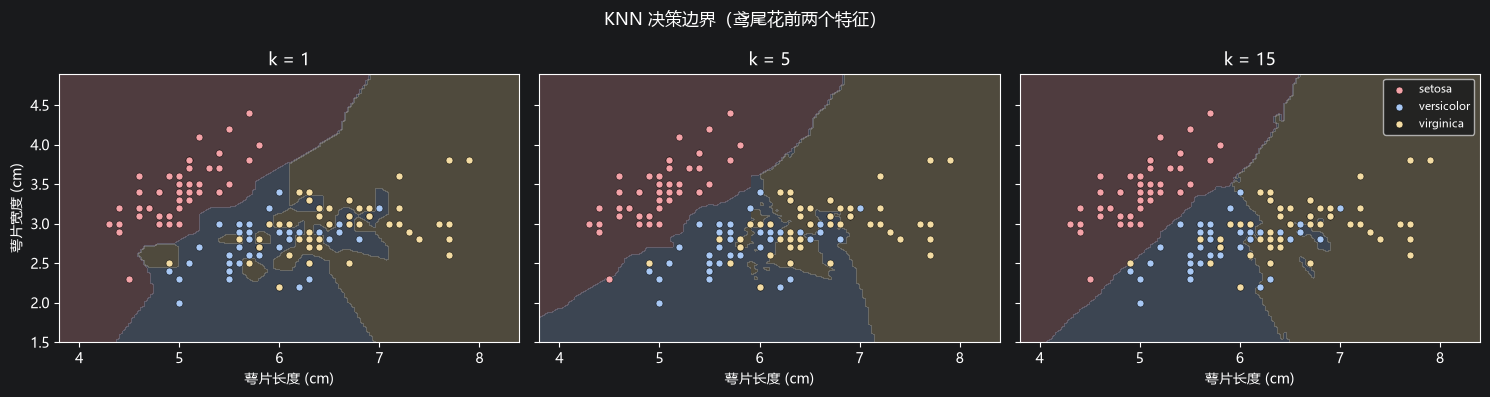

In [23]:
X2 = X[:, :2]

x_min, x_max = X2[:, 0].min() - 0.5, X2[:, 0].max() + 0.5
y_min, y_max = X2[:, 1].min() - 0.5, X2[:, 1].max() + 0.5
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 150),
    np.linspace(y_min, y_max, 150),
)

colors = ["#f4a3a8", "#a8c8f4", "#f4dca3"]
cmap = ListedColormap(colors)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, k in zip(axes, [1, 5, 15]):
    clf = KNeighborsClassifier(n_neighbors=k).fit(X2, y)
    zz = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    ax.contourf(
        xx, yy, zz,
        levels=[-0.5, 0.5, 1.5, 2.5],
        cmap=cmap,
        alpha=0.25,
    )
    for i, name in enumerate(iris.target_names):
        mask = y == i
        ax.scatter(
            X2[mask, 0], X2[mask, 1],
            s=25, color=colors[i], edgecolor="black", linewidth=0.3,
            label=name,
        )
    ax.set_title(f"k = {k}")
    ax.set_xlabel("萼片长度 (cm)")

axes[0].set_ylabel("萼片宽度 (cm)")
axes[-1].legend(fontsize=8)
fig.suptitle("KNN 决策边界（鸢尾花前两个特征）")
fig.tight_layout()
plt.show()

## 11. 小结

一条完整链路：

1. **明确任务**：写清 T、P、E；
2. **准备数据**：样本 × 特征 + 标签；
3. **选择距离**：欧氏 / 曼哈顿 / 切比雪夫，距离也是超参数；
4. **选择 k**：太小过拟合，太大欠拟合，用交叉验证选；
5. **投票方式**：uniform 或 distance；
6. **标准化**：KNN 对量纲敏感，`fit` 只能看训练集；
7. **防泄露**：预处理和特征选择放进 Pipeline；
8. **调参**：GridSearchCV 穷举超参数组合；
9. **最终评估**：测试集只考一次，不参与任何选择。

### 练习

1. 把 `k` 改成 2、10、50，观察决策边界和交叉验证准确率。
2. 比较 `p=1`、`p=2`、`metric="chebyshev"` 在鸢尾花上的差异。
3. 在苹果数据上对比标准化前后的邻居和预测结果。
4. 自己构造一个数据泄露例子，并用 Pipeline 修复。
5. 把 `StandardScaler` 和 `KNeighborsClassifier` 放进同一个 Pipeline，再用 `GridSearchCV` 调参。